# RadioSkySims Uses

Fluxo de exemplo dos serviços do RadioSkySim. Todos os serviços usam uma
**data de referência comum** (1 mês antes de agora) e uma **janela de
24 h com passo de 15 min**. Recursos (fluxo solar, RINEX, TAP) são
buscados localmente (cache) e, se necessário, **online**; se nada for
encontrado, o notebook levanta uma **exceção clara** e segue para as
próximas células.

Cada celula de codigo usa `%%time` e reporta o **tempo de processamento** (wall time) ao final.


## 1. Parâmetros de referência (todos os serviços)

Aqui definimos a data de referência (``REF_DATE`` = 1 mês antes de
agora), a janela de simulação (24 h, passo 15 min) e o observador
padrão (BINGO). Todos os serviços abaixo usam estes parâmetros.


In [1]:
%%time
# ── Âncora de diretório: raiz do projeto (CWD-independente) ──
# Garante que caminhos relativos (ex.: Path("data")) resolvam da raiz do
# projeto, independente de onde o kernel Jupyter iniciou (notebooks/ ou raiz).
import os

from radioskysims_core.paths import get_project_root

os.chdir(get_project_root())
print("cwd →", os.getcwd())

cwd → /share/lbarosi/RadioSkySimSuite
CPU times: user 4 s, sys: 116 ms, total: 4.11 s
Wall time: 1.38 s


In [2]:
%%time
# ── Parâmetros de referência compartilhados por TODOS os serviços ──
from datetime import UTC, datetime, timedelta
from pathlib import Path

import numpy as np

# Data de referência: 1 mês antes de agora (UTC).
REF_DATE = (datetime.now(UTC) - timedelta(days=30)).replace(microsecond=0)
print("Data de referência (REF_DATE):", REF_DATE.isoformat())

# Janela de simulação: 24 h a partir de REF_DATE, passo de 15 min.
# TimeRange.from_iso aceita ISO naive (UTC) — não usa sufixo de timezone.
from radioskysims_core.domain.common import FrequencyRange, TimeRange

_ISO_FMT = "%Y-%m-%dT%H:%M:%S"
TR = TimeRange.from_iso(
    REF_DATE.strftime(_ISO_FMT),
    (REF_DATE + timedelta(hours=24)).strftime(_ISO_FMT),
    60 * 15,
)
print(
    "TimeRange (24 h, 15 min):",
    TR.to_datetime64().shape[0],
    "instantes | resolução:",
    TR.resolution_sec,
    "s",
)

FR = FrequencyRange(min_mhz=1000.0, max_mhz=1250.0, resolution_mhz=0.5)

# Observador de referência (BINGO — região do Uirapuru/RN).
from radioskysims_core.domain.common import Observer

OBSERVER = Observer(lat=-6.2391, lon=-38.9296, height=440.0, timeframe=TR)

# Diretórios de cache local para downloads.
DATA_DIR = Path("data")
RINEX_DIR = DATA_DIR / "rinex"
SOLAR_DIR = DATA_DIR / "solar_flux"
for _d in (RINEX_DIR, SOLAR_DIR):
    _d.mkdir(parents=True, exist_ok=True)


Data de referência (REF_DATE): 2026-10-07T19:21:36+00:00
TimeRange (24 h, 15 min): 97 instantes | resolução: 900.0 s
CPU times: user 1.36 ms, sys: 0 ns, total: 1.36 ms
Wall time: 1.35 ms


In [3]:
%%time


# ── Acesso a recursos: local (cache) → online → raise (e continua) ──
def load_or_download(name, local=None, download=None):
    """Resolve um recurso: usa o cache local se existir; senão baixa online.

    - ``local``: callable que retorna o recurso ou ``None``/``[]`` se ausente.
    - ``download``: callable que obtém o recurso online.
    - Se nem local nem online resolverem, levanta ``RuntimeError`` claro —
      o restante do notebook continua a partir das próximas células.
    """
    if local is not None:
        try:
            found = local()
            if found:
                print(f"[cache] {name}")
                return found
        except Exception:
            pass
    if download is None:
        raise RuntimeError(f"Recurso '{name}' indisponível: sem arquivo local e sem download.")
    print(f"[online] baixando {name} ...")
    try:
        return download()
    except Exception as exc:
        raise RuntimeError(
            f"Recurso '{name}' indisponível: local vazio e online falhou "
            f"({type(exc).__name__}: {exc})"
        ) from exc


CPU times: user 3 μs, sys: 0 ns, total: 3 μs
Wall time: 5.25 μs


### Composition root (injeção de dependências)

Os facades (`SatelliteOrchestrator`, `LocalSourcesOrchestrator` e
`RadioSourcesOrchestrator`) recebem suas fábricas concretas — track via
Skyfield, PSD analítico e repositórios — pelo **composition root**. Isso
é feito **uma única vez** aqui, antes do uso dos serviços.


In [4]:
%%time
# ── Composition root: injeta fábricas concretas nos facades (DI) ──
from radioskysims_sources.bootstrap.builders import configure_facade_defaults

configure_facade_defaults()
print("Facades configurados (Skyfield track + PSD analítico + repositórios).")


Facades configurados (Skyfield track + PSD analítico + repositórios).
CPU times: user 265 ms, sys: 33 ms, total: 298 ms
Wall time: 298 ms


## 2. Radiotelescópio & Beam Properties


RadiotelescopeSpec(name='UIRAPURU Telescope', antennas=1 [BINGO Horn], loc=(-7.2116°, -35.9081°))
Antennas(n=1, names=['BINGO Horn'])
Available properties: FWHM, Gain, BeamPattern, effective_area, beam_width, frequency_range, num_channels, bandwidth, system_temperature


<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
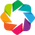

CPU times: user 1.14 s, sys: 130 ms, total: 1.27 s
Wall time: 1.27 s


:Overlay
   .Tiles.I                                                                                                               :Tiles   [x,y]
   .Points.Observer_left_parenthesis_hyphen_minus_7_full_stop_2116_comma_hyphen_minus_35_full_stop_9081_right_parenthesis :Points   [x,y]

In [5]:
%%time
from radioskysims import create_radiotelescope

uirapuru = create_radiotelescope("default")

# Melhor __repr__ do RadiotelescopeSpec (agregado)
print(uirapuru)

# Antennas: __repr__() lista as propriedades disponíveis
print(uirapuru.antennas)

# Visão interativa (holoviews) do observador — mapa com tiles OSM
uirapuru.observer.view()


In [6]:
%%time
# FWHM × frequência (gráfico holoviews)
uirapuru.antennas.get_properties("FWHM").view()
uirapuru.antennas.get_properties("Gain").view()
uirapuru.antennas.get_properties("BeamPattern").view()


CPU times: user 493 ms, sys: 29 ms, total: 522 ms
Wall time: 521 ms


:Overlay
   .Curve.BINGO_Horn_em_dash_1000_MHz :Curve   [Angle (deg)]   (Response (dB))
   .Curve.BINGO_Horn_em_dash_1050_MHz :Curve   [Angle (deg)]   (Response (dB))
   .Curve.BINGO_Horn_em_dash_1125_MHz :Curve   [Angle (deg)]   (Response (dB))
   .Curve.BINGO_Horn_em_dash_1175_MHz :Curve   [Angle (deg)]   (Response (dB))
   .Curve.BINGO_Horn_em_dash_1250_MHz :Curve   [Angle (deg)]   (Response (dB))

## 3. Satellites

Usa o `SatelliteManager` com `REF_DATE` (a data de referência) e a janela
`TR` de 24 h. Requer PostgreSQL (`settings.toml`); se o catálogo local
estiver indisponível, o erro é exibido e o notebook continua.


In [7]:
%%time
# Satélites via SatelliteOrchestrator (fachada) — TLE na data de referência
from radioskysims_sources import SatelliteOrchestrator

try:
    sat_orch = SatelliteOrchestrator.create_from_constellation(
        ["GPS", "GALILEO"],
        epoch=REF_DATE,
    )
    sats = sat_orch.satellites
    print(f"{len(sats)} satélites (deduplicados por NORAD ID) em {REF_DATE:%Y-%m-%d}")
    sat_orch.get_tle()[0]
except Exception as exc:
    print("[aviso] catálogo de satélites indisponível —", type(exc).__name__, str(exc)[:200])


64 satélites (deduplicados por NORAD ID) em 2026-10-07
CPU times: user 1.26 s, sys: 17.8 ms, total: 1.28 s
Wall time: 1.32 s


salvo: /share/lbarosi/RadioSkySimSuite/notebooks/plots/sats_tracks_by_constellation.png


<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
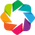

salvo: /share/lbarosi/RadioSkySimSuite/notebooks/plots/sats_signals.html
SatelliteAssembled(32 satélites [GPS BIIR-5 (PRN 22), GPS BIIR-8 (PRN 16), GPS BIIR-11 (PRN 19), GPS BIIR-13 (PRN 02), GPS BIIRM-1 (PRN 17), … (+27)]; tracks {'satellite': 32, 'time': 97, 'xyz': 3}, signals {'satellite': 128, 'freq': 501})
  por constelação: GPS=32


CPU times: user 17 s, sys: 101 ms, total: 17.1 s
Wall time: 17 s


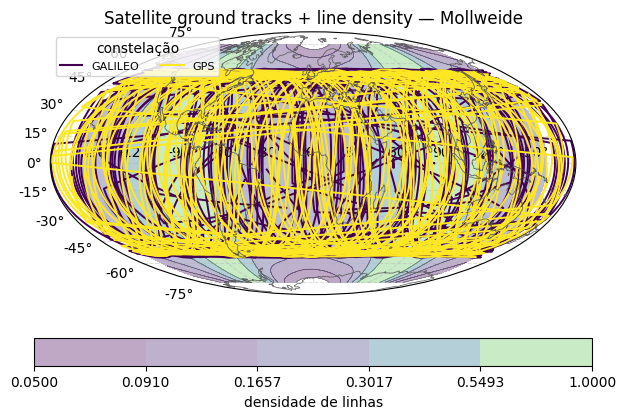

In [8]:
%%time
# build: monta o SatelliteAssembled (tracks + signals) na janela de 24 h
from radioskysims_viz import save_figure, save_plot

try:
    assembled = sat_orch.build(TR, FR)
    assembled  # __repr__ amigável (N satélites + dims)

    # Órbitas-terra (Mollweide): tracks por constelação + contornos de densidade
    fig = assembled.plot_tracks(by="constellation", contours=True)
    fig
    save_figure(fig, "sats_tracks_by_constellation")

    # Espectros PSD × frequência — uma curva por sinal (L1/L2/L5)
    ov = assembled.plot_signals()
    ov
    save_plot(ov, "sats_signals")

    # Seleção por constelação + sinais da seleção
    gps = assembled.select_Constellation("GPS")
    print(gps.summary())
    um = assembled.select_Satellite(noradID=gps.norad_ids[0])
    um.plot_signals()
except Exception as exc:
    print(
        "[aviso] montagem/plot de satélites indisponível (Postgres?) —",
        type(exc).__name__,
        str(exc)[:200],
    )


### Satélites a partir de RINEX (NAV broadcast)

Além do TLE (catálogo), os satélites podem ser criados a partir de
efemérides de transmissão (RINEX **NAV**) — download real (RBMC `pbcg`)
com cache em `data/rinex/`. O `RinexSatelliteManager` segue o **mesmo
fluxo do TLE**: criação → `build_tracks(TR)` → views, usando a mesma
janela de referência `TR`.

[cache] RINEX NAV (pbcg): data/rinex/pbcg2801.26n
NAV: data/rinex/pbcg2801.26n
[cache] RINEX OBS (pbcg): data/rinex/pbcg2801.26d
OBS: data/rinex/pbcg2801.26d
salvo: /share/lbarosi/RadioSkySimSuite/notebooks/plots/rinex_satellites_mollweide.png
salvo: /share/lbarosi/RadioSkySimSuite/notebooks/plots/rinex_satellites_signals.png
Link budget (obs RINEX) — EIRP estimada por banda:
  GPS L1 C/A @  1575.42 MHz: EIRP ~  25.22 dBW (n=32)
  GPS   L1C @  1575.42 MHz: EIRP ~  25.22 dBW (n=32)
  GPS   L2C @  1227.60 MHz: EIRP ~  23.05 dBW (n=32)
  GPS    L5 @  1176.45 MHz: EIRP ~  22.68 dBW (n=32)
Fragmento signals.json (EIRP estimada):
[
  {
    "constellation": "GPS",
    "eirp_dbw": 24.04,
    "rhcp": true,
    "signals": [
      {
        "name": "L5",
        "frequency": "1176.450000 MHz",
        "modulation": "BPSK(10)"
      },
      {
        "name": "L2C",
        "frequency": "1227.600000 MHz",
        "modulation": "BPSK(1)"
      },
      {
        "name": "L1 C/A",
        "frequency

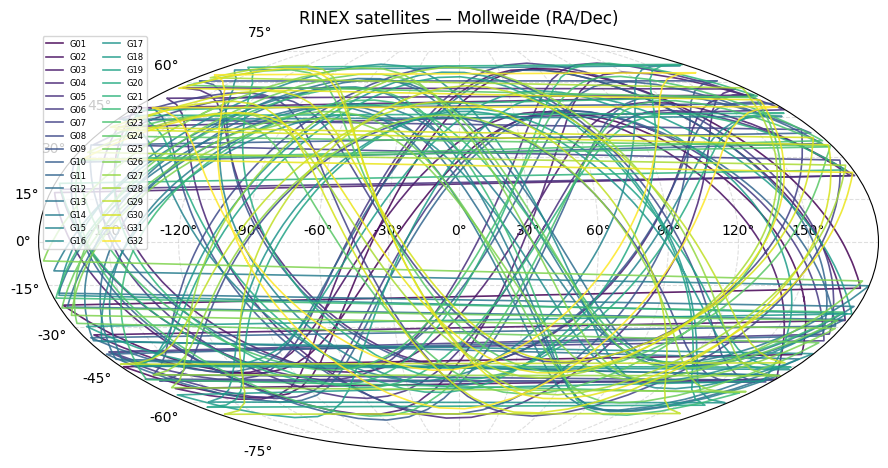

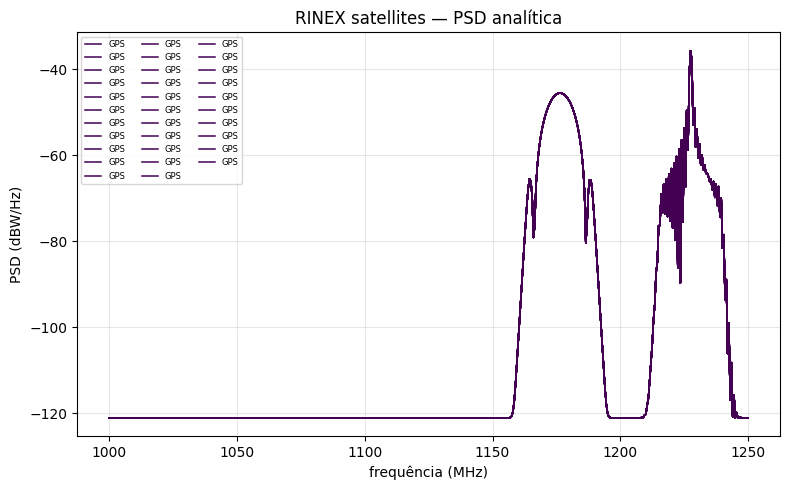

In [9]:
%%time
# Satélites a partir de RINEX — download NAV/OBS + build(TR, FR) (mesmo fluxo do TLE)
from gnsstools4astro.application.services import RinexSatelliteManager
from radioskysims_viz import save_figure

STATION = "pbcg"  # estação RBMC próxima ao BINGO

try:
    # 1) manager configurado para a estação/data
    rmgr = RinexSatelliteManager.for_station(STATION, ref_date=REF_DATE, cache_dir=RINEX_DIR)
    rmgr

    # 2) download NAV (cache local ou online) — necessário p/ tracks/satélites
    nav_path = rmgr.download_nav()
    print("NAV:", nav_path)

    # 3) download OBS (cache local ou online) — usado pelo link budget
    obs_path = rmgr.download_obs()
    if obs_path:
        print("OBS:", obs_path)
    else:
        print("[info] OBS indisponível para a data — link budget não avaliado")

    # 4) build(TR, FR) — como o TLE: monta tracks + signals (PSD analítica)
    rinex_assembled = rmgr.build(TR, FR)
    rinex_assembled  # __repr__: N satélites + dims

    rinex_assembled.summary()
    rmgr.list_satellites()  # satélites carregados (como o get_tle() do TLE)
    rmgr.list_ephemerides()

    # 5) tracks na MESMA janela TR usada pelo TLE
    rinex_assembled.tracks
    fig = rinex_assembled.plot_tracks()
    fig
    save_figure(fig, "rinex_satellites_mollweide")

    # 6) signals — PSD ANALÍTICA (mesmo código do TLE): picos nas portadoras
    rinex_assembled.signals
    fig = rinex_assembled.plot_signals()
    fig
    save_figure(fig, "rinex_satellites_signals")

    # 7) link budget: C/N0 (obs) + range (nav) → EIRP estimada → signals.json
    if obs_path:
        import json as _json
        from gnsstools4astro.application.use_cases import EstimateLinkBudgetUseCase
        from gnsstools4astro.domain.constellations import get_constellation_signals

        estimates = rmgr.estimate_link_budget(obs_path)
        lb = EstimateLinkBudgetUseCase(get_constellation_signals())
        print("Link budget (obs RINEX) — EIRP estimada por banda:")
        for s in lb.summarize(estimates):
            print(
                f"  {s.constellation} {s.band_name:>5} @ {s.frequency_mhz:8.2f} MHz: "
                f"EIRP ~ {s.eirp_dbw_mean:6.2f} dBW (n={s.n_satellites})"
            )
        print("Fragmento signals.json (EIRP estimada):")
        print(
            _json.dumps(
                lb.to_signals_reference(estimates, base=get_constellation_signals()), indent=2
            )
        )
except Exception as exc:
    print("[aviso] RINEX indisponível (sem local/online) —", type(exc).__name__, str(exc)[:200])


## 4. Local Sources (Sun)

O Sol usa **fluxo solar real calibrado** do NoRP/Nobeyama (formato
XDR, *absolute measurements*) com cache local em `data/solar_flux/`
e track via Skyfield no observador de referência.


In [ ]:
%%time
# Sun — fluxo solar REAL (NoRP/Nobeyama) com cache local + track via Skyfield
import pandas as pd
import xarray as xr

from radioskysims_viz import save_figure
from radioskysims_sources import LocalSourcesOrchestrator
from radioskysims_sources.domain.localsources import SolarFlux
from radioskysims_sources.infrastructure.external.nro_solar_flux_downloader import (
    NroSolarFluxDownloader,
)

SOLAR_NC = SOLAR_DIR / f"solar_nro_{REF_DATE:%Y%m%d}.nc"


def _solar_from_cache(nc: Path):
    ds = xr.open_dataset(nc)
    t = ds["time"].values.astype("datetime64[ns]")
    return SolarFlux(
        start_utc=pd.Timestamp(np.datetime64(t[0], "s")).to_pydatetime(),
        end_utc=pd.Timestamp(np.datetime64(t[-1], "s")).to_pydatetime(),
        dataset=ds,
        source_url=f"cache:{nc.name}",
    )


# Fluxo solar real (cache → online); se falhar, usa Sol calmo (fallback).
try:
    solar_flux = load_or_download(
        name="fluxo solar (NoRP/Nobeyama)",
        local=lambda: _solar_from_cache(SOLAR_NC) if SOLAR_NC.exists() else None,
        download=lambda: NroSolarFluxDownloader(timeout_sec=60).fetch(
            center_utc=REF_DATE, window_hours=24
        ),
    )
    if not SOLAR_NC.exists():
        try:
            solar_flux.dataset.to_netcdf(SOLAR_NC)
            print("  cache salvo:", SOLAR_NC)
        except Exception as _exc:
            print("  [aviso] não foi possível salvar cache do fluxo solar:", _exc)
    print("fluxo solar:", solar_flux.source_url)
except Exception as exc:
    print(
        "[aviso] fluxo solar online indisponível — usando Sol calmo:",
        type(exc).__name__,
        str(exc)[:200],
    )
    solar_flux = None

# Sun com o fluxo real (ou Sol calmo) + track no observador de referência
sun = LocalSourcesOrchestrator.create_sun(observer=OBSERVER, time_range=TR, flux=solar_flux)
print(sun.summary())
sun

# Carta do céu local ALT/AZ (matplotlib, deferido ao viz)
fig = sun.view_skychart()
fig
save_figure(fig, "sun_skychart")

# RA/Dec do Sol no mapa Mollweide (com continentes)
fig = sun.view_mollweide()
fig
save_figure(fig, "sun_mollweide")

# Fluxo solar × frequência (holder com .view())
fig = sun.flux_density().view()
fig
save_figure(fig, "sun_flux_density")

## 5. Radio Sources

O `RadioSourcesOrchestrator` carrega o **catálogo real** (banco `radio_sources`,
re-ingerido via TAP NVSS+SPECFIND) ou, sem banco, cai para um catálogo
simulado. Também é possível ingerir **NVSS + SPECFIND reais via TAP/ADQL
(VizieR)** na hora (rede necessária).

**Índice espectral (α):** fontes sem medida SPECFIND usam um **prior de
sincrotrão** (determinístico por fonte) — o catálogo real agora tem α
variando, em vez de todas com 0.7.

In [ ]:
%%time
# RadioSources: catálogo real (banco radio_sources) — re-ingerido via TAP
from radioskysims_viz import save_figure
from radioskysims_sources import RadioSourcesOrchestrator

# Carrega do banco (323 fontes NVSS reais, α variando). Alternativa demo:
#   radiosources = RadioSourcesOrchestrator.simulated(n_sources=40, seed=7)
radiosources = RadioSourcesOrchestrator.from_db()
radiosources  # __repr__ amigável (N fontes)

df = radiosources.list_properties()
print(
    "índices espectrais (α):",
    df["alpha"].nunique(),
    "únicos |",
    round(df["alpha"].min(), 3),
    "-",
    round(df["alpha"].max(), 3),
)
df

fig = radiosources.view_mollweide()
fig
save_figure(fig, "radio_sources_mollweide")

fig = radiosources.view_flux_density()
fig
save_figure(fig, "radio_sources_flux_density")

# Seleção por critérios + fluxo da seleção
bright = radiosources.select(min_flux_jy=1.0)
print(f"{len(bright)} fontes com S0 >= 1 Jy")
fig = bright.view_flux_density()
fig
save_figure(fig, "radio_sources_bright_flux")

# ── TAP real (VizieR): re-ingerir NVSS + SPECFIND numa janela do céu ──
# Fontes sem medida SPECFIND usam um prior de α (não ficam todas em 0.7).
try:
    tap = RadioSourcesOrchestrator.from_tap(
        ra_min_deg=180.0,
        ra_max_deg=200.0,
        dec_min_deg=-5.0,
        dec_max_deg=5.0,
        smin_jy=0.1,
    )
    print(f"{len(tap)} fontes NVSS reais (TAP VizieR)")
    tap_df = tap.list_properties()
    print("  α reais:", tap_df["alpha"].round(3).nunique(), "únicos")
    tap_df
    fig = tap.view_flux_density()
    fig
    save_figure(fig, "radio_sources_tap_flux")
except Exception as exc:
    print("[aviso] TAP indisponível (sem rede?) —", type(exc).__name__, str(exc)[:200])

índices espectrais (α): 323 únicos | 0.0 - 1.47
salvo: /share/lbarosi/RadioSkySimSuite/notebooks/plots/radio_sources_mollweide.png
salvo: /share/lbarosi/RadioSkySimSuite/notebooks/plots/radio_sources_flux_density.png
12 fontes com S0 >= 1 Jy
salvo: /share/lbarosi/RadioSkySimSuite/notebooks/plots/radio_sources_bright_flux.png


## Próximos passos

Este notebook cobre radiotelescópio, satélites (TLE/RINEX), Sol e fontes de
rádio. Para os demais fluxos do RadioSkySim, veja:

- `01_maps.ipynb` — mapas de céu (SkyMap).
- `02_sims.ipynb` — simulação de TOD.
- `03_waterfall.ipynb` — waterfall (canal × tempo).
